# Tuokkola et al. near-millisecond transmon sample (Aalto / VTT): a Quantcore-PDK rebuild, step by step

**Source:** M. Tuokkola, Y. Sunada, H. Kivijärvi, J. Albanese, L. Grönberg, J.-P. Kaikkonen, V. Vesterinen,
J. Govenius, M. Möttönen, *Methods to achieve near-millisecond energy relaxation and dephasing times for a
superconducting transmon qubit* (arXiv 2407.18778).
- Data and GDS: Zenodo record 14651787, **CC BY 4.0**, read from the local copy `components/Zenodo_files/`.
- The sample: `sample.gds`, chip `EITR2` (10 × 10 mm, centred on (0, 0)); its layers are copied into
  `examples/designs/community/tuokkola_near_ms_transmon_sample.oas`.

Spec: `docs/designs/community/tuokkola_near_ms_transmon.md`.

**What the chip is (read from the GDS):** four floating two-pad transmons, Q1/Q3 with SQUIDs and Q2/Q4 with single
junctions. Pockets are 800 × 1000 µm, pads 400 × 300 µm with a 20 µm gap, and each has a coupler bar. Readout goes
through four λ/4s, each with 900 µm of coupled line on one U-shaped λ/2 Purcell filter. The filter sits between an
input finger capacitor and an interdigital output capacitor (feed CPW 21/11 µm). Two drive lines are each shared by
a pair of qubits. The whole ground plane carries a hole grid.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source (`sample.gds`, EITR2) | this rebuild |
|---|---|---|
| die and frame | 10 × 10 mm, labels `EITR2` / `1-0`, corner marks | PDK frame on the same 10 × 10 mm die, device ID `EITR2-QCT` |
| stack | sapphire | PDK sapphire 650 µm, εr 10.25 |
| qubits | two-pad transmons, Q1/Q3 SQUID, Q2/Q4 single junction | `metal:TransmonPocket6` with the GDS sizes; Quantcore trilayer SQUIDs / junctions sized for the measured f_q (R_n and f_q outside the PDK margins are flagged, not retuned) |
| Purcell filter | U-shaped λ/2 between two capacitors | a qcc CPW route on the GDS's runs between two `FingerCapacitorSquare`s with the GDS's finger counts |
| readouts | four meandered λ/4s, 900 µm coupled to the filter | qcc λ/4 hangers on the filter, centred where the GDS has them (`near=`) |
| pads | launchpads 850–940 µm from the die edge | **PDK pad rule**: outer etch `frame.pad_edge` = 100 µm from the die edge |
| placement | circuit left of centre (the right edge holds a junction test column) | the test column is not rebuilt, so **the circuit is centred** in the die |
| cheese | a whole-chip hole grid: 20 µm squares, 40 µm pitch, ≥ 80 µm from all etch, ≈ 0.3 mm from the chip edge | **the original wins**: the same grid as the chip's `cheese` rule, drawn by the build and kept in the mask (no PDK band) |
| not rebuilt | labels, junction test column, an unconnected meander | – |

The measured qubit and readout frequencies are the targets (step 3; to be checked against the paper). The last
snapshots render the sample's own chip next to the rebuild.

## 1 · Setup and the PDK

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change shows up live; with `QCC_LIVE=0` (tests, batch
runs) the snapshots are rendered headless. `sizing_md` tabulates the junction sizing against the PDK junction rule.

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.circuit.bridges import size_junction, tl_resonator
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)


def sizing_md(sizing):
    """Trilayer junction sizing (``circuit.bridges.size_junction``) against the PDK junction rule."""
    rows = ["| qubit | f_q target (GHz) | C_Σ (fF) | L_J (nH) | R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |",
            "|---|---|---|---|---|---|---|"]
    for name, s in sizing.items():
        rows.append(f"| {name} | {s.f_q_GHz:.3f} | {s.c_sigma_fF:.1f} | {s.lj_nH:.2f} | {s.rn_kohm:.1f} | "
                    f"{s.f_q_drawn_GHz:.3f} | {'yes' if s.rn_in_window else 'no'} |")
    return "\n".join(rows)

The PDK facts this chip relies on. The frame and the cheese are drawn by the chip build, the pad rule by `edge=`, the junctions by
`trilayer_junction`; the PDK design warnings come out of the DRC.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 2 · The die and the frame

The sample is a 10 × 10 mm chip, so the rebuild keeps that die (the box is in µm; Designer = source + (5000, 5000)).
The PDK draws its frame round it: the L dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary
(100/0) and the device ID `EITR2-QCT` on a free edge.

**Cheese.** The sample's ground plane has its own hole grid (`sample.gds`: 20 µm squares on a 40 µm pitch, at least
80 µm from all etch, the field reaching to 0.29–0.39 mm from the chip edge), so the original wins: the chip carries
that grid as its `cheese` rule (`size`, `gap`, `rows`, `clearance`, `edge`) and the build draws it instead of the PDK
band (layout, snapshots, KLive and the mask). The rule's `clearance` is measured from the 3/0 keep-out, which already
adds the PDK route margin (10 µm) round each CPW, so 80 − 10 = 70 µm keeps the holes 80 µm from the line etch, as in
the sample (and 94 µm from the pockets, whose keep-out margin is 24 µm). `edge` 300 µm is the sample's margin to the
chip edge.

chip cheese rule: {'size': 20.0, 'gap': 20.0, 'rows': 1000, 'clearance': 70.0, 'edge': 300.0}


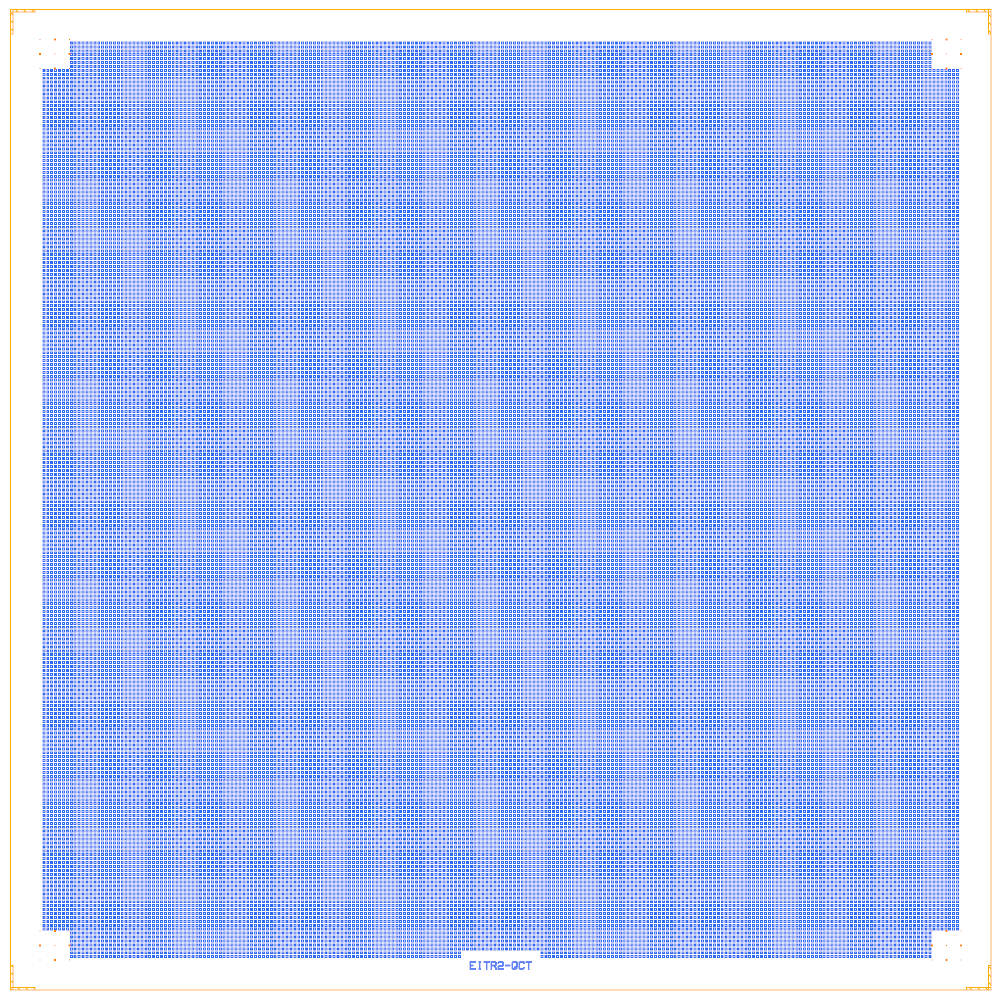

In [3]:
from quantcore_circuits.pdk import get_pdk

X0 = Y0 = 5000.0                                   # source chip (10 × 10 mm) is centred on (0, 0)
HOLES = {"size": 20.0, "gap": 20.0, "rows": 1000,  # the sample's grid: 20 µm squares on a 40 µm pitch,
         "clearance": 80.0 - get_pdk().keepout.route_margin,   # 80 µm from the line etch (3/0 adds 10 µm)
         "edge": 300.0}                            # ≈ the sample's margin to the chip edge
d = Designer("tuokkola_near_ms_transmon", box=(0, 0, 10000, 10000),
             chip={"name_chip": "EITR2-QCT", "cheese": HOLES}, live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
snap(d, OUT / "tuokkola_near_ms_transmon_die.png", size=(1000, 1000), width=360);

## 3 · Components

**Targets and junction sizing.** The measured qubit frequencies (paper, first cooldown) set the junctions:
`size_junction(f_q, C_Σ, n)` finds the L_J that gives f_q at the pocket's LOM C_Σ (96 fF, from the netlist in step 7),
for one junction (Q2, Q4) or a symmetric SQUID (n = 2: Q1, Q3), and the R_n and finger sizes of the drawn trilayer
junction. These qubits sit at 2.9–4.6 GHz, at or below the PDK's 4–8 GHz band, so every R_n lands above the 40–50 kΩ
window (75–188 kΩ as drawn; for the SQUIDs, the device's parallel R_n). Following the project rule they are flagged (DRC `pdk_rn`, `pdk_fq`), not retuned.

In [4]:
SITES = {  # name: ((x, y) source µm, rot, SQUID?, f_q target GHz (paper, first cooldown))
    "Q1": ((-100, 2513), 0, True, 4.047),
    "Q2": ((1400, 2513), 0, False, 2.890),
    "Q3": ((1400, -2513), 180, True, 4.593),
    "Q4": ((-100, -2513), 180, False, 3.295),
}
C_SIGMA = 96.0                                     # fF: LOM C_Σ of this pocket (step 7), sizes the junctions
SIZING = {q: size_junction(f, C_SIGMA, n=2 if sq else 1) for q, (_, _, sq, f) in SITES.items()}
display(Markdown(sizing_md(SIZING)))

| qubit | f_q target (GHz) | C_Σ (fF) | L_J (nH) | R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |
|---|---|---|---|---|---|---|
| Q1 | 4.047 | 96.0 | 14.62 | 97.7 | 4.135 | no |
| Q2 | 2.890 | 96.0 | 27.60 | 184.4 | 2.865 | no |
| Q3 | 4.593 | 96.0 | 11.48 | 76.7 | 4.647 | no |
| Q4 | 3.295 | 96.0 | 21.58 | 144.2 | 3.339 | no |

**The qubits.** `metal:TransmonPocket6` (Quantum Metal's pocket transmon through the `metal:` wrapper) with the GDS's
sizes: pads 400 × 300 µm, gap 20 µm, pocket 800 × 1000 µm. The coupler bar is a centred 400 × 20 µm connection pad
40 µm below the pad, its 11/5 µm lead running to the pocket edge (the port `readout`). `trilayer_junction(...,
squid=...)` returns the cell parameters that draw the Quantcore SQUID or single junction (fingers 2/0 + 4/0, spacer
50/0 + 51–53/0) and the junction values the LOM uses.

In [5]:
POCKET = dict(pad_width=400, pad_height=300, pad_gap=20, pocket_width=800, pocket_height=1000,
              connection_pads=dict(readout=dict(loc_W=0, loc_H=-1, pad_width=400, pad_height=20, pad_gap=40,
                                                pad_cpw_shift=0, pad_cpw_extent=0, cpw_width=11, cpw_gap=5,
                                                cpw_extend=0)))
q = {}
with d.batch():
    for name, ((x, y), rot, squid, f) in SITES.items():
        params, jj = trilayer_junction("metal:TransmonPocket6", lj_nH=SIZING[name].lj_nH, squid=squid)
        q[name] = d.add(name, "metal:TransmonPocket6", at=(X0 + x, Y0 + y), rot=rot, junction=jj, **POCKET, **params)
        print(name, params["junction_type"], jj)

Q1 Quantcore Squid {'Lj_nH': 14.03, 'Cj_fF': 7.2}
Q2 Quantcore Junction {'Lj_nH': 28.0601, 'Cj_fF': 3.6}
Q3 Quantcore Squid {'Lj_nH': 11.224, 'Cj_fF': 9.0}
Q4 Quantcore Junction {'Lj_nH': 21.0451, 'Cj_fF': 4.8}


**The filter capacitors.** Both are KQC `FingerCapacitorSquare`s with the GDS's finger counts and lengths, on the
source's 21/11 µm feed CPW: the input one (2 fingers × 100 µm) at the top left, the interdigital output one
(7 fingers × 500 µm) at the bottom left. Their ports `a` (feed side) and `b` (filter side) carry the routes.

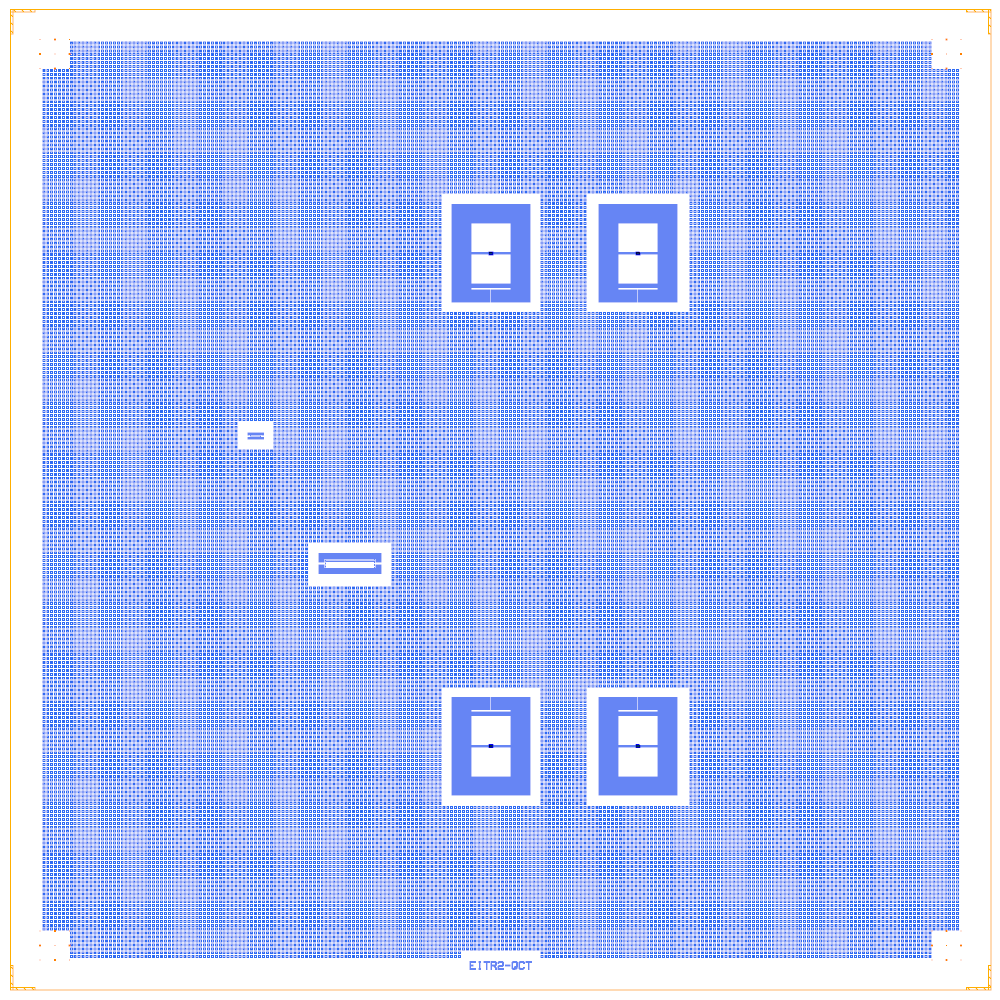

In [6]:
FEED = dict(a=21, b=11)                            # the source's filter / feed CPW
Y_TOP, Y_BOT, X_U = Y0 + 650, Y0 - 650, X0 + 1816  # filter runs and its U (from the GDS)
with d.batch():
    cin = d.add("CIN", "FingerCapacitorSquare", at=(X0 - 2500, Y_TOP), finger_number=2, finger_width=10,
                finger_gap=5, finger_length=100, finger_gap_end=5, ground_padding=20, **FEED)
    cout = d.add("COUT", "FingerCapacitorSquare", at=(X0 - 1536, Y_BOT), finger_number=7, finger_width=11,
                 finger_gap=4, finger_length=500, finger_gap_end=4, ground_padding=56, **FEED)
snap(d, OUT / "tuokkola_near_ms_transmon_components.png", size=(1000, 1000), width=360);

## 4 · Routes: the Purcell filter and the four readouts

**The filter** is a plain CPW (`type="cpw"`, no meander) from `CIN.b` along the top run, round the U at x = +1816 µm
(bend radius 180 µm) and back along the bottom run to `COUT.b`: the waypoints are the GDS's.

**The readouts** are λ/4s on the PDK stack: L = v_ph / 4f for the 11/5 µm CPW, −7 % for the pull of the coupler bar's
C_g and of the hanger, as calibrated once in the LOM. Each starts at its qubit's coupler bar, meanders (r 50 µm) and
ends in `pf.hanger(...)`: 900 µm of line coupled to the filter across a 31 µm ground strip, shorted at its far end.
`near=(x, y)` centres the coupler at the filter point nearest (x, y): 450 µm left of the qubit, as in the GDS. A coupler
given by `near=` stays put when the filter's start moves; `direction` sets which end is shorted.

In [7]:
F_R = dict(Q1=5.85, Q2=5.977, Q3=6.103, Q4=6.23)  # paper: 5.85–6.23 GHz; assigned by the GDS resonator lengths
VP = tl_resonator(4500, 11, 5)["vp_m_s"]           # PDK stack (sapphire), 11/5 µm CPW (the source's readout CPW)
L_RO = {q_: round(VP / (4 * f * 1e9) * 1e6 * 0.930, 1) for q_, f in F_R.items()}   # λ/4, −7 % (C_g + hanger pull)
HG = dict(length=900, side="left", ground_gap=31, end="short")
with d.batch():
    pf = d.route("PF", cin.b, cout.b, type="cpw", nodes=[(X_U, Y_TOP), (X_U, Y_BOT)], r=180, **FEED)   # the U filter
    for name, ((x, y), rot, squid, f) in SITES.items():
        near = (X0 + x - 450, Y_TOP if y > 0 else Y_BOT)                  # coupler centre: 450 µm left of the qubit
        d.route(f"R_{name}", q[name].readout,
                pf.hanger(near=near, direction="backward" if y > 0 else "forward", **HG),
                meander=L_RO[name], r=50, a=11, b=5)
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
print("λ/4 targets (µm):", L_RO)

{'PF': 8412.0, 'R_Q1': 5017.6, 'R_Q2': 4911.0, 'R_Q3': 4809.6, 'R_Q4': 4711.6}
λ/4 targets (µm): {'Q1': 5017.6, 'Q2': 4911.0, 'Q3': 4809.6, 'Q4': 4711.6}


## 5 · PDK placement: centre the circuit, then the pad rule

**Centring.** The sample's circuit sits left of the die centre because its right edge holds a junction test column,
which the rebuild does not draw. `center_in_die(d)` measures the bounding box of every instance and route (the qubits,
the capacitors, the filter and the readouts so far) and shifts all of them so that box is centred. This is done before
the pads: they are pinned to the die edges by the pad rule and would drag the centring.

In [8]:
shift = center_in_die(d)
print("shift applied (µm):", shift)
X0, Y0 = X0 + shift[0], Y0 + shift[1]             # the source origin in Designer coordinates from here on
Y_TOP, Y_BOT = Y0 + 650, Y0 - 650
print("content box after centring:", content_box(d))

shift applied (µm): (383.2, 0.0)


content box after centring: (2800.7,1987;7199.2,8013)


**The pad rule.** The sample's launchpads sit 850–940 µm inside the die. The PDK puts every bond pad and launcher with
the outer edge of its etch **`frame.pad_edge` = 100 µm from the die edge**. `edge="auto"` slides each pad
perpendicular to its nearest die edge until that holds and keeps its position along the edge: the two filter ports go
to the west edge at the filter's heights, the two drive pads to the north and south edges above and below the gap
between the qubit pairs. `pads_md(d)` lists each pad's distance to the nearest edge.

In [9]:
LP_FEED = dict(trace_width=21, trace_gap=11, pad_width=250, pad_height=250, pad_gap=80, taper_height=120)
with d.batch():
    lp_in = d.add("LP_IN", "metal:LaunchpadWirebond", at=(X0 - 3700, Y_TOP), edge="auto", **LP_FEED)
    lp_out = d.add("LP_OUT", "metal:LaunchpadWirebond", at=(X0 - 3700, Y_BOT), edge="auto", **LP_FEED)
    lp_dt = d.add("LP_DT", "metal:LaunchpadWirebond", at=(X0 + 650, Y0 + 3800), rot=-90, edge="auto",
                  trace_width=11, trace_gap=5)
    lp_db = d.add("LP_DB", "metal:LaunchpadWirebond", at=(X0 + 650, Y0 - 3800), rot=90, edge="auto",
                  trace_width=11, trace_gap=5)
rebuild(d)
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP_IN | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_OUT | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_DT | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| LP_DB | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

**Feed and drive lines.** The feed lines join the launchpads to the filter capacitors; with the pads at the edge they
are longer than in the sample (a 50 Ω line: its length does not set any frequency). The two drive lines, each shared
by a qubit pair, end open (5 µm gap) between the pockets: `Designer.free_end(at, dir, term)` is a route end that is not
a port. Then the sim groups (one per qubit with its readout and the filter) and the targets.

{'PF': 8412.0, 'R_Q1': 5017.6, 'R_Q2': 4911.0, 'R_Q3': 4809.6, 'R_Q4': 4711.6, 'FEED_IN': 2225.7, 'FEED_OUT': 2953.2, 'DRIVE_T': 1947.5, 'DRIVE_B': 1947.5}


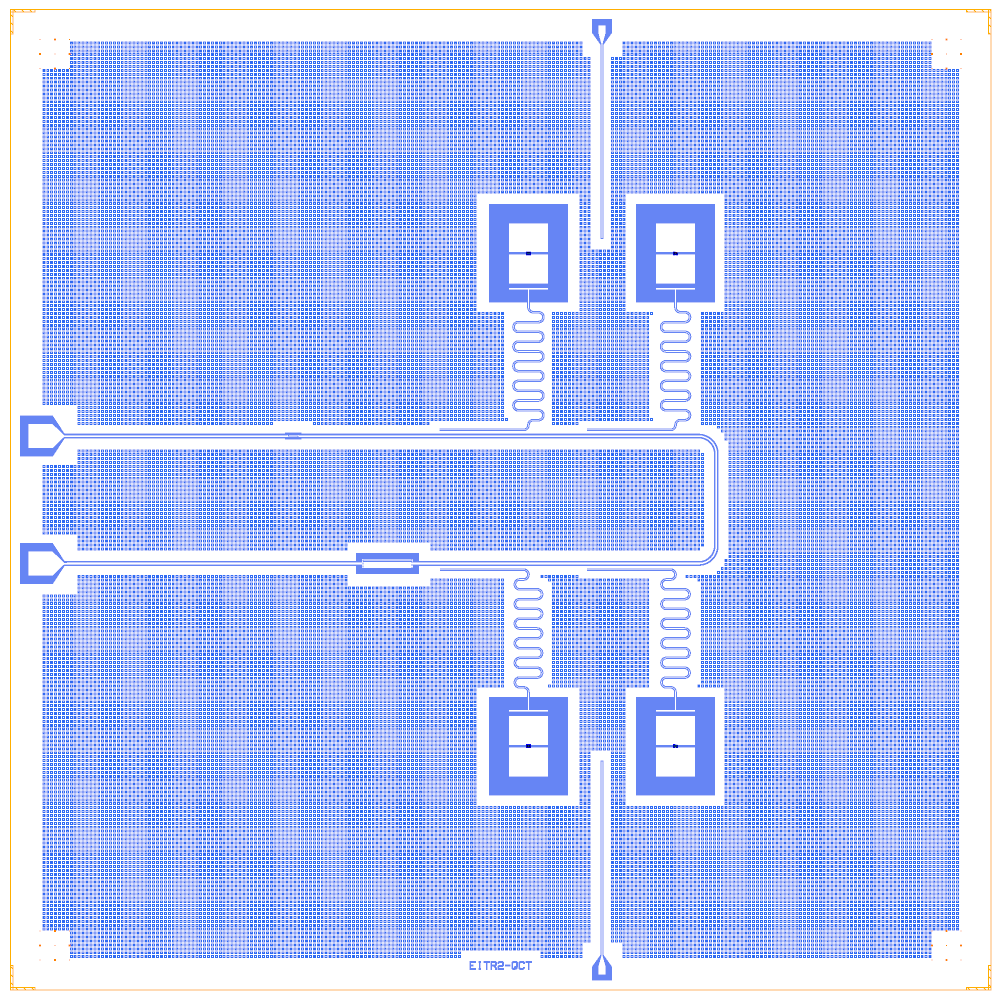

In [10]:
with d.batch():
    d.route("FEED_IN", lp_in.tie, cin.a, **FEED)
    d.route("FEED_OUT", cout.a, lp_out.tie, **FEED)
    d.route("DRIVE_T", lp_dt.tie, Designer.free_end((X0 + 650, Y0 + 2667.5), dir=90, term=5), a=11, b=5)
    d.route("DRIVE_B", lp_db.tie, Designer.free_end((X0 + 650, Y0 - 2667.5), dir=-90, term=5), a=11, b=5)
    for name in SITES:
        d.sim_group(f"{name}R", [name, f"R_{name}", "PF", "CIN", "COUT"])
    d.targets(**{n: {"f_q_GHz": f} for n, (_, _, _, f) in SITES.items()},
              **{f"R_{n}": {"f_GHz": f} for n, f in F_R.items()})
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "tuokkola_near_ms_transmon_routes.png", size=(1000, 1000), width=360);

## 6 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK
margins. There are three kinds of finding:
- **errors** would make the chip wrong; there must be none;
- **warnings** are worth a look but can be intended: here the junction attachment points (`squid_a` / `squid_b`; the
  cell draws its own junction);
- **PDK design warnings** flag values outside the PDK margins: `pdk_rn` (R_n outside 40–50 kΩ) on every qubit and
  `pdk_fq` on Q2 and Q4 (targets below 4 GHz). They are reported, never enforced.

Expected (this run): **no errors**; 8 `dangling_port` warnings (`squid_a` / `squid_b`); 4 `pdk_rn` (Q1 93.7, Q2 187.5,
Q3 75.0, Q4 140.6 kΩ) and 2 `pdk_fq` (Q2 2.89, Q4 3.295 GHz). No `pad_edge`: the four launchpads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks: cheese source, centring, junction types, design warnings.

In [11]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 8 warnings · 6 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 8 | Q1.squid_a is not connected (no route or snap) |
| PDK design warning | `pdk_fq` | 2 | Q2: f_q target 2.89 GHz is outside the PDK band 4–8 GHz |
| PDK design warning | `pdk_rn` | 4 | Q1: junction R_n 93.7 kΩ is outside the PDK window 40–50 kΩ (L_J 14.03 nH) |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 20, gap 20, rows 1000, clearance 70, edge 300 |
| content centre − die centre | (-1350, +0) µm |
| junction types | Quantcore Squid × 2, Quantcore Junction × 2 |
| PDK design warnings | 6 (pdk_rn × 4, pdk_fq × 2) |
| pdk_rn | Q1: junction R_n 93.7 kΩ is outside the PDK window 40–50 kΩ (L_J 14.03 nH) |
| pdk_rn | Q2: junction R_n 187.5 kΩ is outside the PDK window 40–50 kΩ (L_J 28.0601 nH) |
| pdk_rn | Q3: junction R_n 75.0 kΩ is outside the PDK window 40–50 kΩ (L_J 11.224 nH) |
| pdk_rn | Q4: junction R_n 140.6 kΩ is outside the PDK window 40–50 kΩ (L_J 21.0451 nH) |
| pdk_fq | Q2: f_q target 2.89 GHz is outside the PDK band 4–8 GHz |
| pdk_fq | Q4: f_q target 3.295 GHz is outside the PDK band 4–8 GHz |

The content centre is west of the die centre because the two filter launchpads are pinned to the west edge; the
circuit itself was centred in step 5 (this run: the circuit moved by (+383, 0) µm; with the pads and feed lines the
content centre is (−1350, 0) µm). "The original design's rule (drawn in the build)" is the cheese decision: the
sample's hole grid, no PDK band.

## 7 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit:
- four floating transmons (`Q<n>.island1/2` and the junction between them; Q1/Q3 with SQUIDs);
- four λ/4 readouts (`TLres`), each with a `HANGER` (κ) to the filter node `PF`;
- the filter: a λ/2 between `CIN` and `COUT`, with a 50 Ω port behind each capacitor;
- two drive lines (open ends between the pockets).

In [12]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

**18 nodes · 48 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.readout` | `Q1.readout` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.readout` | `Q2.readout` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.readout` | `Q3.readout` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |
| `Q4.readout` | `Q4.readout` |
| `CIN.a` | `CIN.a`, `LP_IN.pad` |
| `CIN.b` | `CIN.b`, `COUT.b` |
| `COUT.a` | `COUT.a`, `LP_OUT.pad` |
| `LP_DT.pad` | `LP_DT.pad` |
| `LP_DB.pad` | `LP_DB.pad` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 80.6 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 80.6 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 45.4 fF |
| `J_Q1` | SQUID | `Q1.island1` – `Q1.island2` | Lj 14 nH, Cj 7.2 fF |
| `Cg_Q1_readout` | C | `Q1.island2` – `Q1.readout` | 32.8 fF |
| `Cf_Q1_readout` | C | `Q1.island1` – `Q1.readout` | 3.4 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 34.2 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 80.6 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 80.6 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 45.4 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 28.1 nH, Cj 3.6 fF |
| `Cg_Q2_readout` | C | `Q2.island2` – `Q2.readout` | 32.8 fF |
| `Cf_Q2_readout` | C | `Q2.island1` – `Q2.readout` | 3.4 fF |
| `Cc_Q2_readout` | C | `Q2.readout` – `gnd` | 34.2 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 80.6 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 80.6 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 45.4 fF |
| `J_Q3` | SQUID | `Q3.island1` – `Q3.island2` | Lj 11.2 nH, Cj 9 fF |
| `Cg_Q3_readout` | C | `Q3.island2` – `Q3.readout` | 32.8 fF |
| `Cf_Q3_readout` | C | `Q3.island1` – `Q3.readout` | 3.4 fF |
| `Cc_Q3_readout` | C | `Q3.readout` – `gnd` | 34.2 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 80.6 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 80.6 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 45.4 fF |
| `J_Q4` | JJ | `Q4.island1` – `Q4.island2` | Lj 21 nH, Cj 4.8 fF |
| `Cg_Q4_readout` | C | `Q4.island2` – `Q4.readout` | 32.8 fF |
| `Cf_Q4_readout` | C | `Q4.island1` – `Q4.readout` | 3.4 fF |
| `Cc_Q4_readout` | C | `Q4.readout` – `gnd` | 34.2 fF |
| `C_CIN` | C | `CIN.a` – `CIN.b` | 10.9 fF |
| `C_CIN_a` | C | `CIN.a` – `gnd` | 6.5 fF |
| `C_CIN_b` | C | `CIN.b` – `gnd` | 6.5 fF |
| `C_COUT` | C | `COUT.a` – `CIN.b` | 232 fF |
| `C_COUT_a` | C | `COUT.a` – `gnd` | 30 fF |
| `C_COUT_b` | C | `CIN.b` – `gnd` | 30 fF |
| `Port_LP_IN` | R | `CIN.a` – `gnd` | 50 Ω |
| `Port_LP_OUT` | R | `COUT.a` – `gnd` | 50 Ω |
| `Port_LP_DT` | R | `LP_DT.pad` – `gnd` | 50 Ω |
| `Port_LP_DB` | R | `LP_DB.pad` – `gnd` | 50 Ω |
| `R_Q1` | TLres | `Q1.readout` – `gnd` | lambda/4, 5018 µm, 6.290 GHz |
| `K_R_Q1` | HANGER | `Q1.readout` – `CIN.b` | κ 0.00917 MHz (L 900 µm) |
| `R_Q2` | TLres | `Q2.readout` – `gnd` | lambda/4, 4911 µm, 6.427 GHz |
| `K_R_Q2` | HANGER | `Q2.readout` – `CIN.b` | κ 0.00977 MHz (L 900 µm) |
| `R_Q3` | TLres | `Q3.readout` – `gnd` | lambda/4, 4810 µm, 6.562 GHz |
| `K_R_Q3` | HANGER | `Q3.readout` – `CIN.b` | κ 0.0104 MHz (L 900 µm) |
| `R_Q4` | TLres | `Q4.readout` – `gnd` | lambda/4, 4712 µm, 6.699 GHz |
| `K_R_Q4` | HANGER | `Q4.readout` – `CIN.b` | κ 0.011 MHz (L 900 µm) |
| `DRIVE_T` | TLres | `LP_DT.pad` – `gnd` | lambda/2, 1948 µm, 32.413 GHz |
| `DRIVE_B` | TLres | `LP_DB.pad` – `gnd` | lambda/2, 1948 µm, 32.413 GHz |

**Unconnected ports:** none

{'nodes': 17, 'branches': 48, 'controls': 0, 'unconnected': 0}


## 8 · LOM simulation

Each qubit is simulated with its readout and the whole filter chain (QuCat normal modes, then QuTiP dressed values).
The measured values are in brackets. This run: f_q 2.830–4.483 GHz, 0.3–2.4 % below the
targets; f_r 5.8445–6.1917 GHz, within 0.6 %; α −206 … −241 MHz; χ −1.36 … −4.21 MHz. κ_r comes out 9–11 kHz, far
too small: the LOM lumps the filter section between its two series
capacitors (an open LOM request, as for metal/m52), so the Purcell-filtered κ needs the FEM.

In [13]:
feed = ["PF", "CIN", "COUT", "FEED_IN", "FEED_OUT", "LP_IN", "LP_OUT"]
GROUPS = {f"{n}R": [n, f"R_{n}", *feed] for n in SITES}
res = simulate_groups(d, GROUPS, max_modes=3)
display(Markdown(groups_md(res, d.data["targets"])))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1R | Q1 | 4.023 (4.047) | -214.5 | R_Q1 | 5.8445 (5.85) | 0.00918 | -3.05 |
| Q2R | Q2 | 2.8299 (2.89) | -241.2 | R_Q2 | 5.9571 (5.977) | 0.00973 | -1.36 |
| Q3R | Q3 | 4.4826 (4.593) | -206 | R_Q3 | 6.0819 (6.103) | 0.0102 | -4.21 |
| Q4R | Q4 | 3.2841 (3.295) | -229.8 | R_Q4 | 6.1917 (6.23) | 0.0108 | -1.56 |

## 9 · FEM: send the job

Each qubit-plus-readout group (with the filter) is exported as a Q3D C-matrix job (capacitances by net name:
`Q<n>.island1`, `Q<n>.island2`, …) and as an eigenmode/EPR job. Job folders are self-contained
(`build/jobs/<design>_<group>_<analysis>`); exporting again replaces a folder, results included. Simulation exports
never carry cheese.

`RUN_FEM = False` only exports. With `RUN_FEM = True` and AEDT 2024 R1 (or newer) on this machine, `send_fem_jobs`
solves each job in a **new batch, non-graphical AEDT** (`solve_job`); an AEDT window you have open is never touched. On another
machine: `qcc hfss solve build/jobs/<job>`.

In [14]:
RUN_FEM = False                                  # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
DESIGN = d.save(OUT / "tuokkola_near_ms_transmon.json")
groups = list(d.data["sim_groups"])
jobs = export_sims(DESIGN, groups, analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, groups, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    send_fem_jobs(DESIGN, groups, analyses=["q3d_cmatrix", "eigenmode_epr"], run=True)

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R | `build/jobs/tuokkola_near_ms_transmon_Q1R_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.readout`<br>3 · edge · `DRIVE_T`<br>4 · edge · `FEED_IN`<br>5 · edge · `FEED_OUT` | `Q1.island2`, `Q1.readout`, `DRIVE_T`, `FEED_IN`, `FEED_OUT`, `CIN.b`, `Q1.island1`, `floating` |
| Q2R | `build/jobs/tuokkola_near_ms_transmon_Q2R_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.readout`<br>3 · edge · `DRIVE_T`<br>4 · edge · `FEED_IN`<br>5 · edge · `FEED_OUT` | `Q2.island2`, `Q2.readout`, `DRIVE_T`, `FEED_IN`, `FEED_OUT`, `CIN.b`, `floating`, `Q2.island1` |
| Q3R | `build/jobs/tuokkola_near_ms_transmon_Q3R_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `Q3.readout`<br>3 · edge · `DRIVE_B`<br>4 · edge · `FEED_IN`<br>5 · edge · `FEED_OUT` | `Q3.island2`, `Q3.readout`, `DRIVE_B`, `FEED_IN`, `FEED_OUT`, `Q3.island1`, `floating`, `CIN.b` |
| Q4R | `build/jobs/tuokkola_near_ms_transmon_Q4R_q3d_cmatrix` | 1 · junction · `Q4.junction`<br>2 · waveguide · `Q4.readout`<br>3 · edge · `DRIVE_B`<br>4 · edge · `FEED_IN`<br>5 · edge · `FEED_OUT` | `Q4.island2`, `Q4.readout`, `DRIVE_B`, `FEED_IN`, `FEED_OUT`, `Q4.island1`, `floating`, `CIN.b` |
| Q1R | `build/jobs/tuokkola_near_ms_transmon_Q1R_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `DRIVE_T`<br>3 · edge_lumped · `FEED_IN`<br>4 · edge_lumped · `FEED_OUT` | `Q1.island2`, `DRIVE_T`, `FEED_IN`, `FEED_OUT`, `CIN.b`, `Q1.island1`, `floating` |
| Q2R | `build/jobs/tuokkola_near_ms_transmon_Q2R_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `DRIVE_T`<br>3 · edge_lumped · `FEED_IN`<br>4 · edge_lumped · `FEED_OUT` | `Q2.island2`, `DRIVE_T`, `FEED_IN`, `FEED_OUT`, `CIN.b`, `floating`, `Q2.island1` |
| Q3R | `build/jobs/tuokkola_near_ms_transmon_Q3R_eigenmode_epr` | 1 · junction · `Q3.junction`<br>2 · edge_lumped · `DRIVE_B`<br>3 · edge_lumped · `FEED_IN`<br>4 · edge_lumped · `FEED_OUT` | `Q3.island2`, `DRIVE_B`, `FEED_IN`, `FEED_OUT`, `Q3.island1`, `floating`, `CIN.b` |
| Q4R | `build/jobs/tuokkola_near_ms_transmon_Q4R_eigenmode_epr` | 1 · junction · `Q4.junction`<br>2 · edge_lumped · `DRIVE_B`<br>3 · edge_lumped · `FEED_IN`<br>4 · edge_lumped · `FEED_OUT` | `Q4.island2`, `DRIVE_B`, `FEED_IN`, `FEED_OUT`, `Q4.island1`, `floating`, `CIN.b` |

## 10 · Bring the results back

When a job has results (`build/jobs/<job>/results/results.json`), `fill(model, design, job)` puts the extracted
capacitances into the LOM by net name, next to the estimates, and the LOM can be simulated again on them. Until a
solve has run, the cell says what would appear.

In [15]:
filled, md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                         **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(md))

No FEM results yet for Q1R · q3d, Q2R · q3d, Q3R · q3d, Q4R · q3d, Q1R · eigenmode, Q2R · eigenmode, Q3R · eigenmode, Q4R · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 11 · Iterate: change one property and re-simulate

The LOM is cheap, so a design change can be checked in seconds. Here Q2's readout is shortened by 150 µm (≈ 3 %): its
λ/4 moves up by about 3 % (this run: 5.957 → 6.131 GHz). The qubit sits ≈ 3 GHz below its readout, so f_q, α and χ
hardly move (f_q stays 2.830 GHz, χ −1.359 → −1.372 MHz).
`design_copy` opens a second, non-live Designer on the saved design, so the design file stays as it is.

In [16]:
d2 = design_copy(DESIGN)
d2["R_Q2"].set(meander=L_RO["Q2"] - 150)
res2 = simulate_groups(d2, {"Q2R": GROUPS["Q2R"]}, max_modes=3)
display(Markdown(params_delta_md({"Q2R": res["Q2R"]}, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q2R: Q2.f_q_GHz` | 2.8299 | 2.8299 | +6.132e-05 |
| `Q2R: Q2.alpha_MHz` | -241.21 | -241.25 | -0.03987 |
| `Q2R: R_Q2.chi_MHz` | -1.3587 | -1.372 | -0.01328 |
| `Q2R: R_Q2.f_GHz` | 5.9571 | 6.131 | +0.1739 |
| `Q2R: R_Q2.kappa_MHz` | 0.0097322 | 0.010557 | +0.0008252 |

## 12 · Build and export

- **Design file:** `d.save(...)` wrote `examples/designs/community/tuokkola_near_ms_transmon.json` (step 9);
  `Designer.load` reopens it.
- **Fab mask, with the original's cheese.** `export_fab` writes only the PDK fab layers (negative mask) with corner
  rounding, and keeps the cheese the build drew: the sample's hole grid (the chip's `cheese` rule, step 2; `cheese
  source: build`, no PDK band added). The 3/0 margins are 10 µm round routes and 24 µm round components, so with the
  rule's 70 µm the holes stay ≥ 80 µm from the routes' etch (the sample's clearance) and ≥ 94 µm from the pockets';
  every hole is on 3/0 as well as on 1/0. The grid is aligned to the die, not to the sample's grid, so it is shifted
  by part of a pitch.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (this chip has none); cheese is never exported.
- **Command line:** `qcc build examples/designs/community/tuokkola_near_ms_transmon.json` (layout + sidecar),
  `qcc design drc …`, `qcc mask …` (the fab file, with
  the build's hole grid), `qcc sim build … -g Q1R -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [17]:
FAB = Path("build") / "tuokkola_near_ms_transmon_fab.oas"
rebuild(d)
display(Markdown(fab_layers_md(d, path=FAB, cheese=True, rounding=True)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 46875 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 46869 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 12 |
| 51/0 | SPACER_1 | 12 |
| 52/0 | SPACER_2 | 12 |
| 53/0 | SPACER_3 | 12 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 46859 holes on the mask.

→ `build/tuokkola_near_ms_transmon_fab.oas`

## 13 · Snapshots

- the full die (compare the sample below: the same four pockets, the U filter between its two capacitors, the
  readouts hanging on the filter runs, the two shared drive lines);
- Q2 with its readout meander and its trilayer junction;
- the output interdigital capacitor;
- the cheese: the same corner of Q2's pocket in the fab mask (left) and in the sample (right);
- the sample's own chip, rendered from its GDS layers (it is not part of the design JSON).

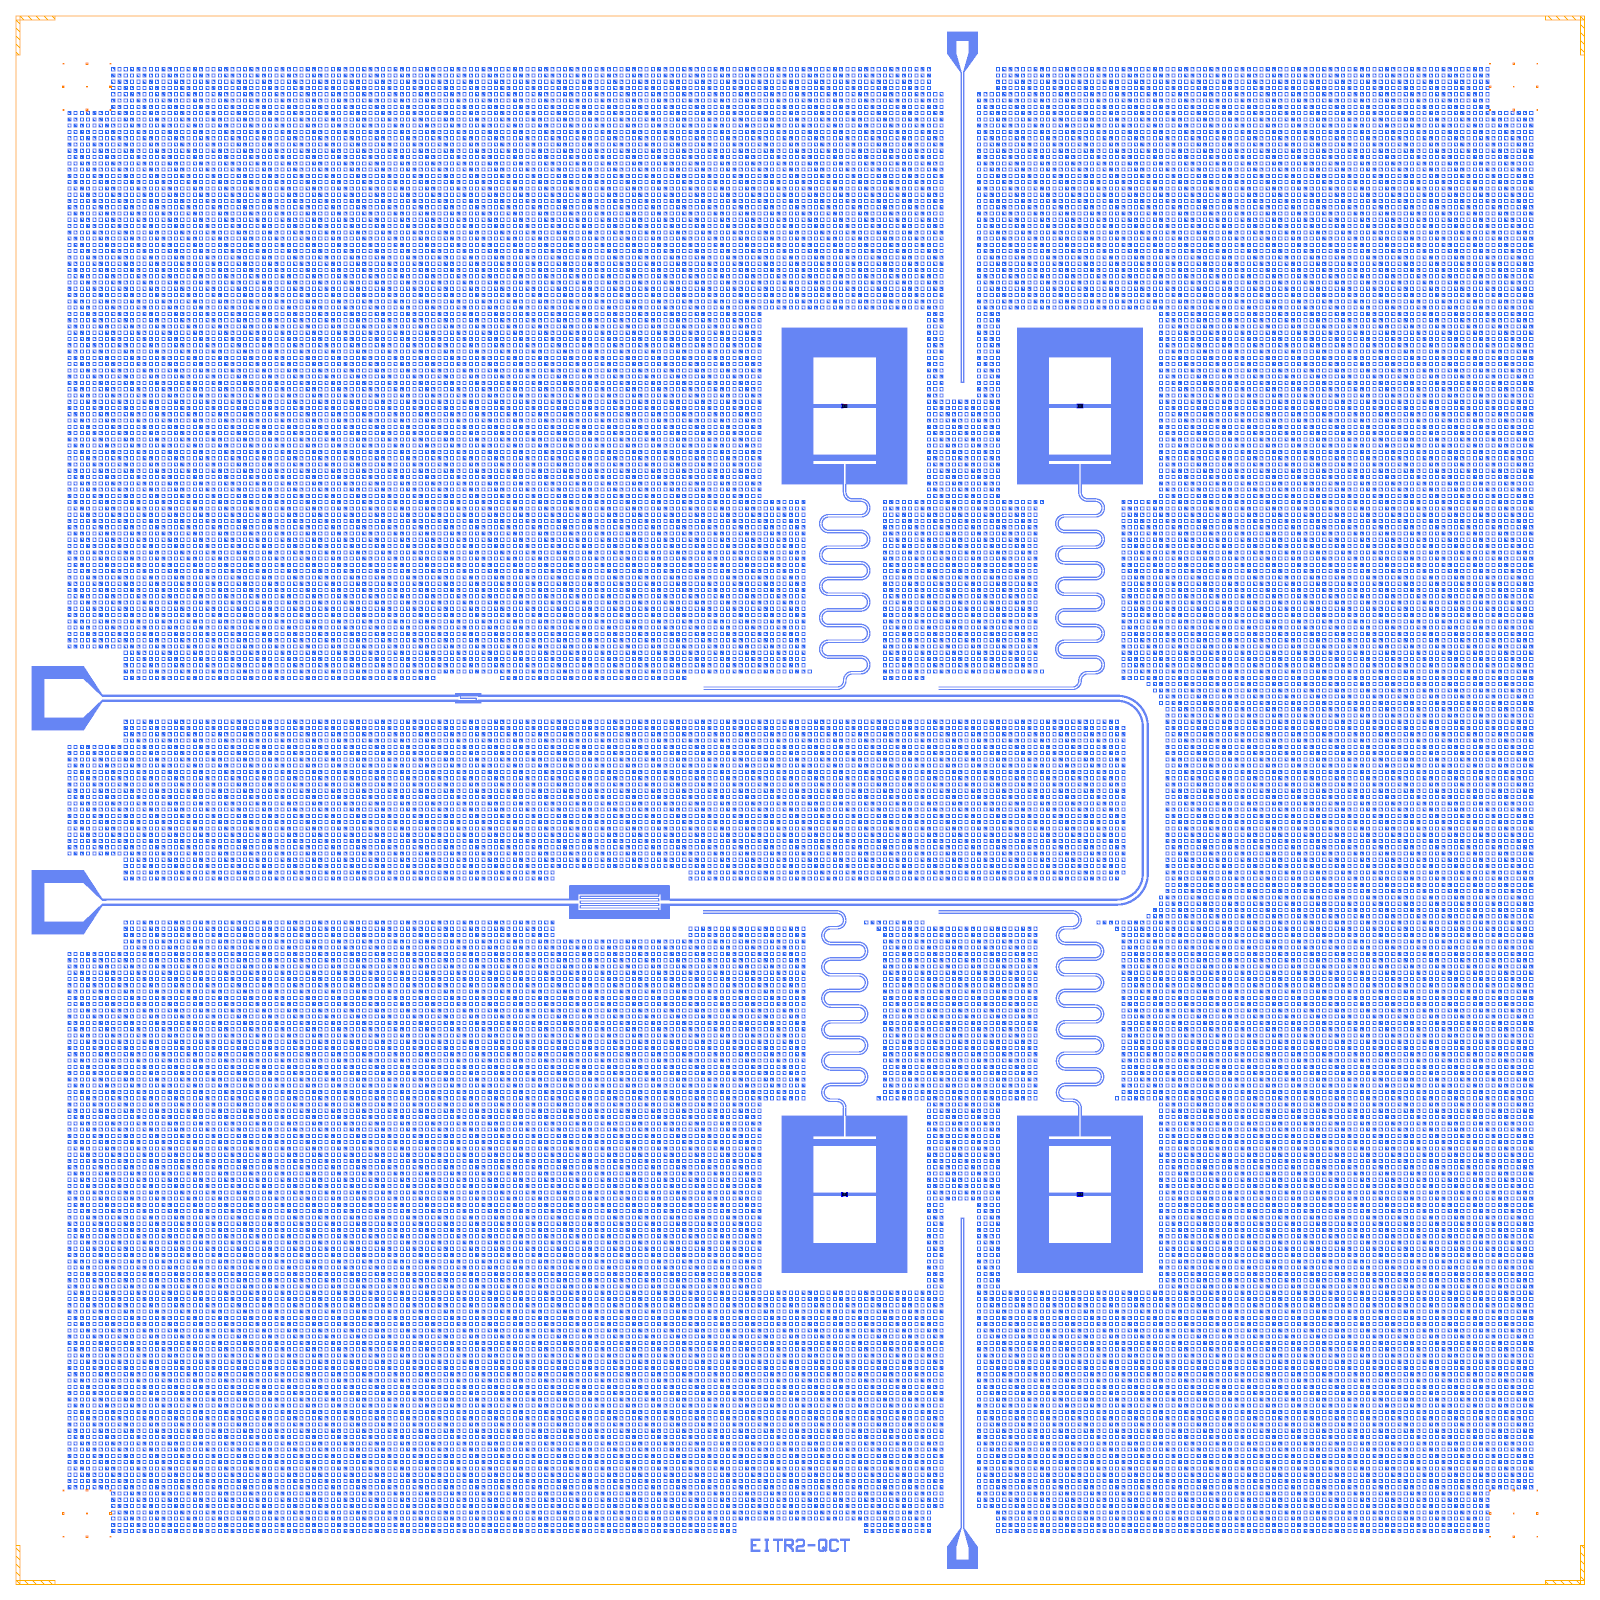

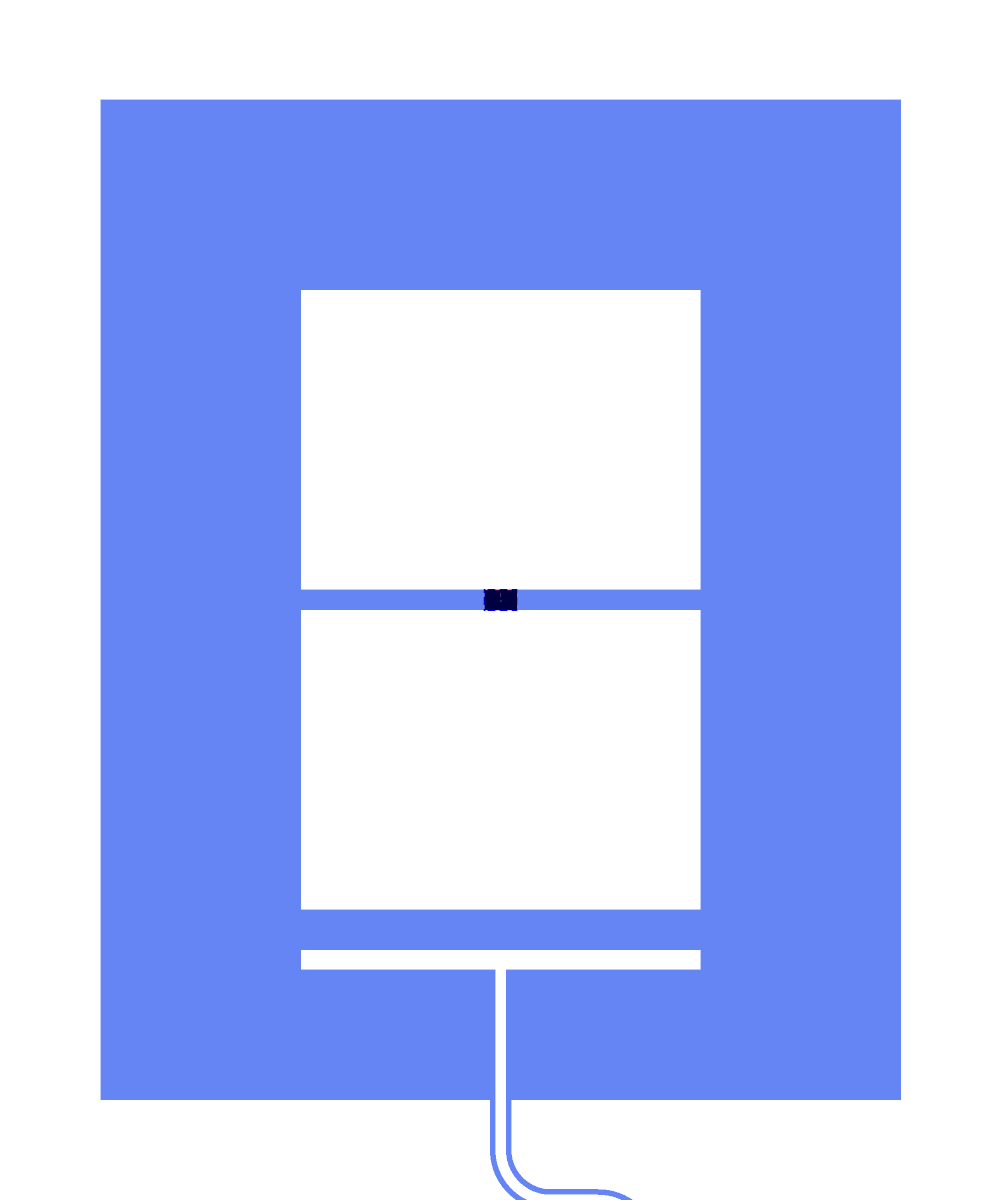

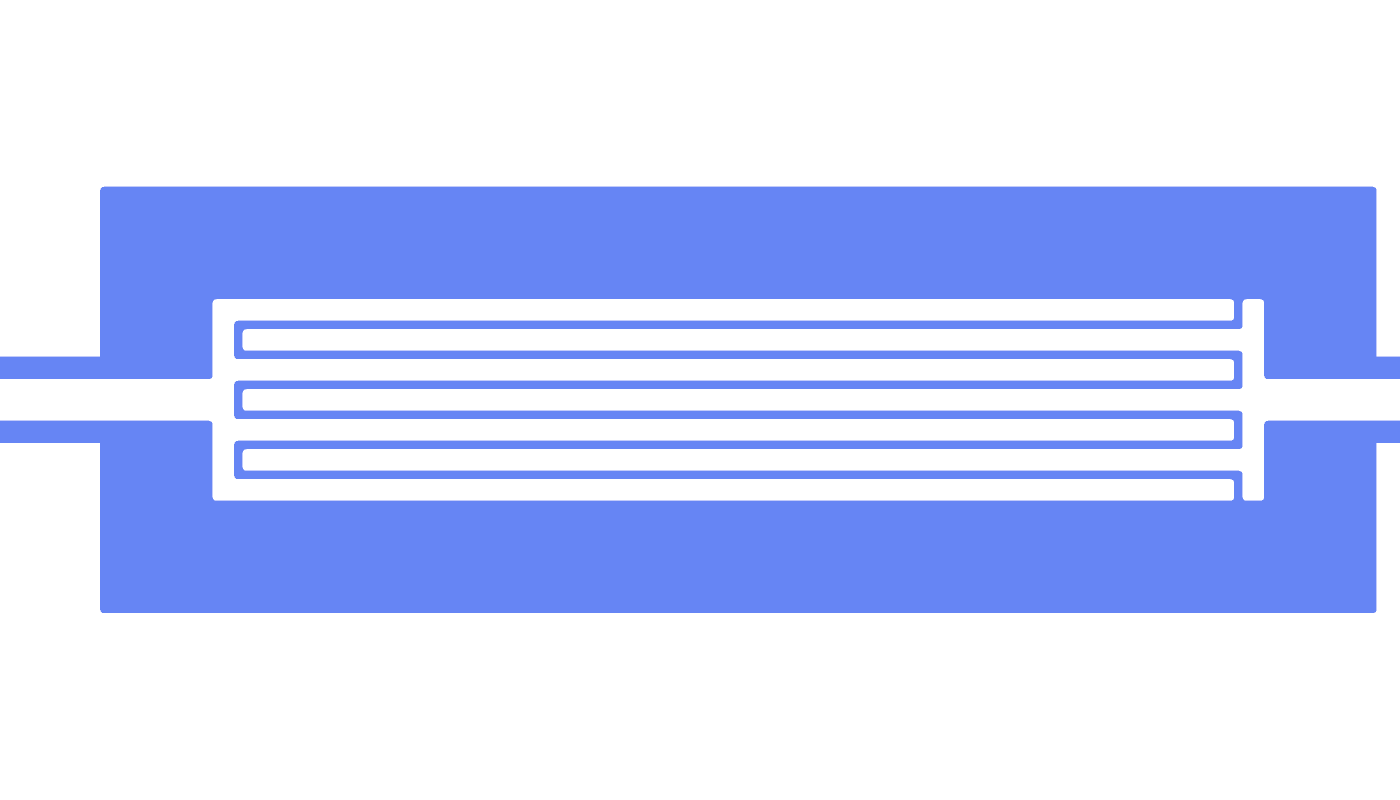

In [18]:
snap(d, OUT / "tuokkola_near_ms_transmon.png", size=(1600, 1600))
x, y = X0 + SITES["Q2"][0][0], Y0 + SITES["Q2"][0][1]
snap(d, OUT / "tuokkola_near_ms_transmon_q2.png", box=(x - 500, y - 600, x + 500, y + 600), size=(1000, 1200), width=400)
cx, cy = port_xy(d, "COUT.a")
snap(d, OUT / "tuokkola_near_ms_transmon_cout.png", box=(cx - 50, cy - 200, cx + 650, cy + 200),
     size=(1400, 800), width=560);

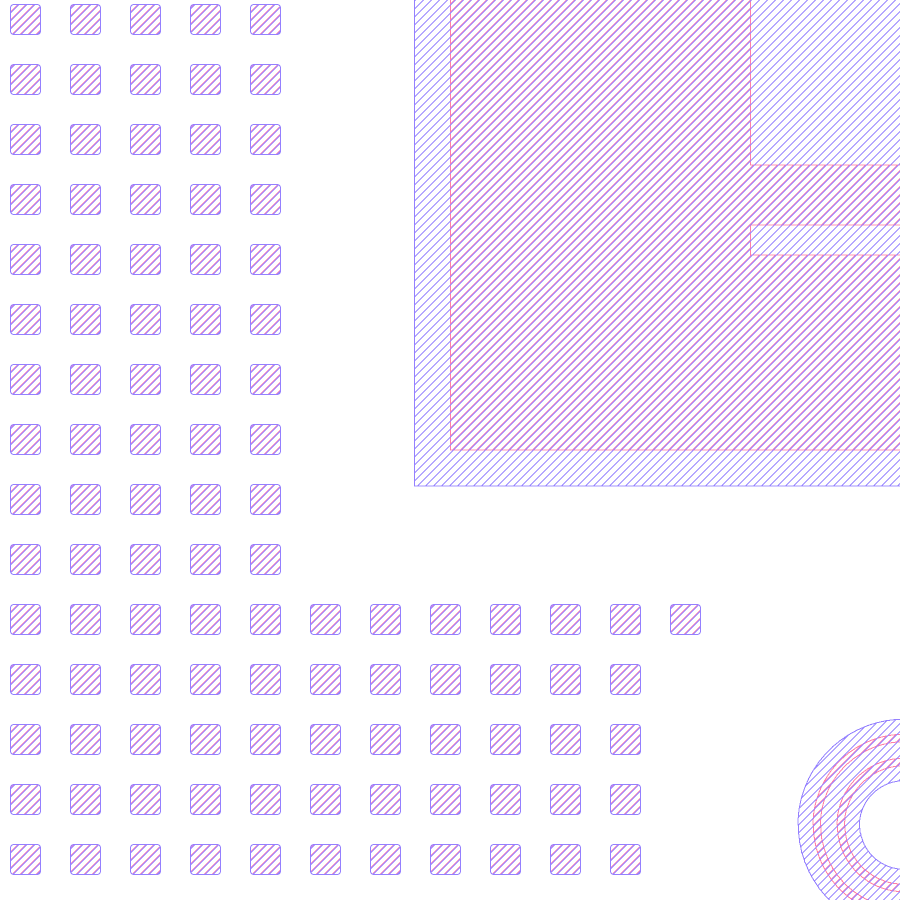

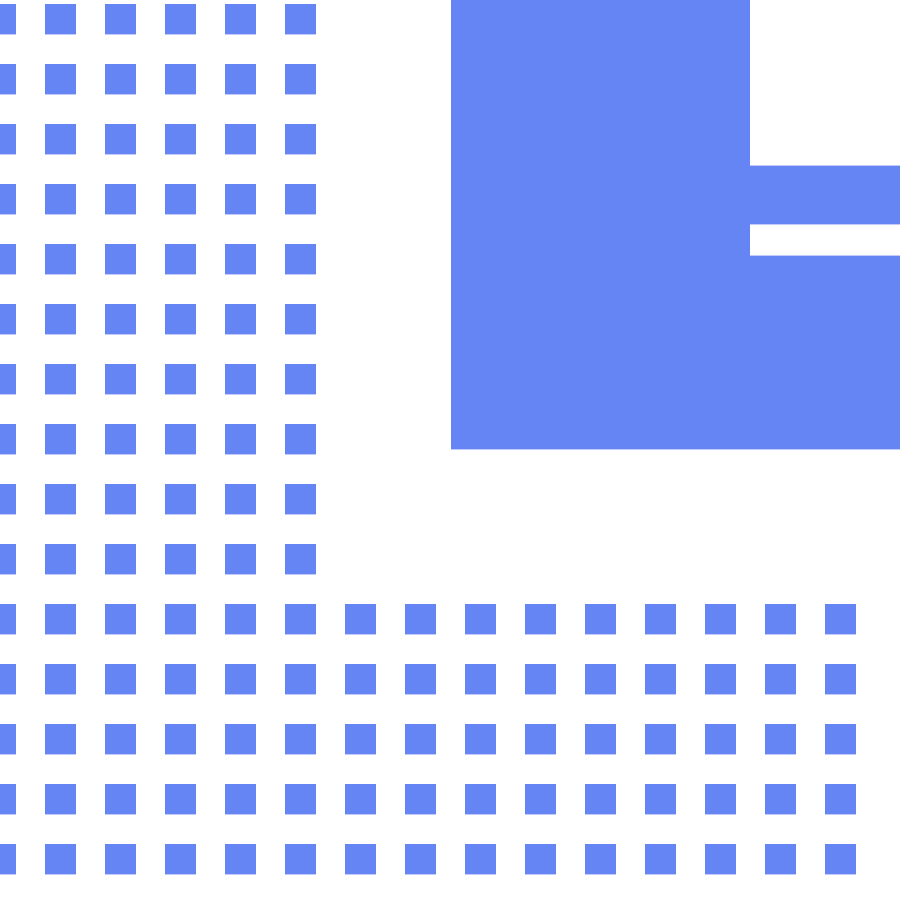

In [19]:
sx, sy = SITES["Q2"][0]                            # Q2 in source coordinates; its pocket's south-west corner
src_box = (sx - 700, sy - 800, sx - 100, sy - 200)
snap_file(FAB, OUT / "tuokkola_near_ms_transmon_cheese.png",
          box=(X0 + src_box[0], Y0 + src_box[1], X0 + src_box[2], Y0 + src_box[3]), size=(900, 900), width=320)
snap_file(OUT / "tuokkola_near_ms_transmon_sample.oas", OUT / "tuokkola_near_ms_transmon_cheese_reference.png",
          box=src_box, size=(900, 900), width=320);

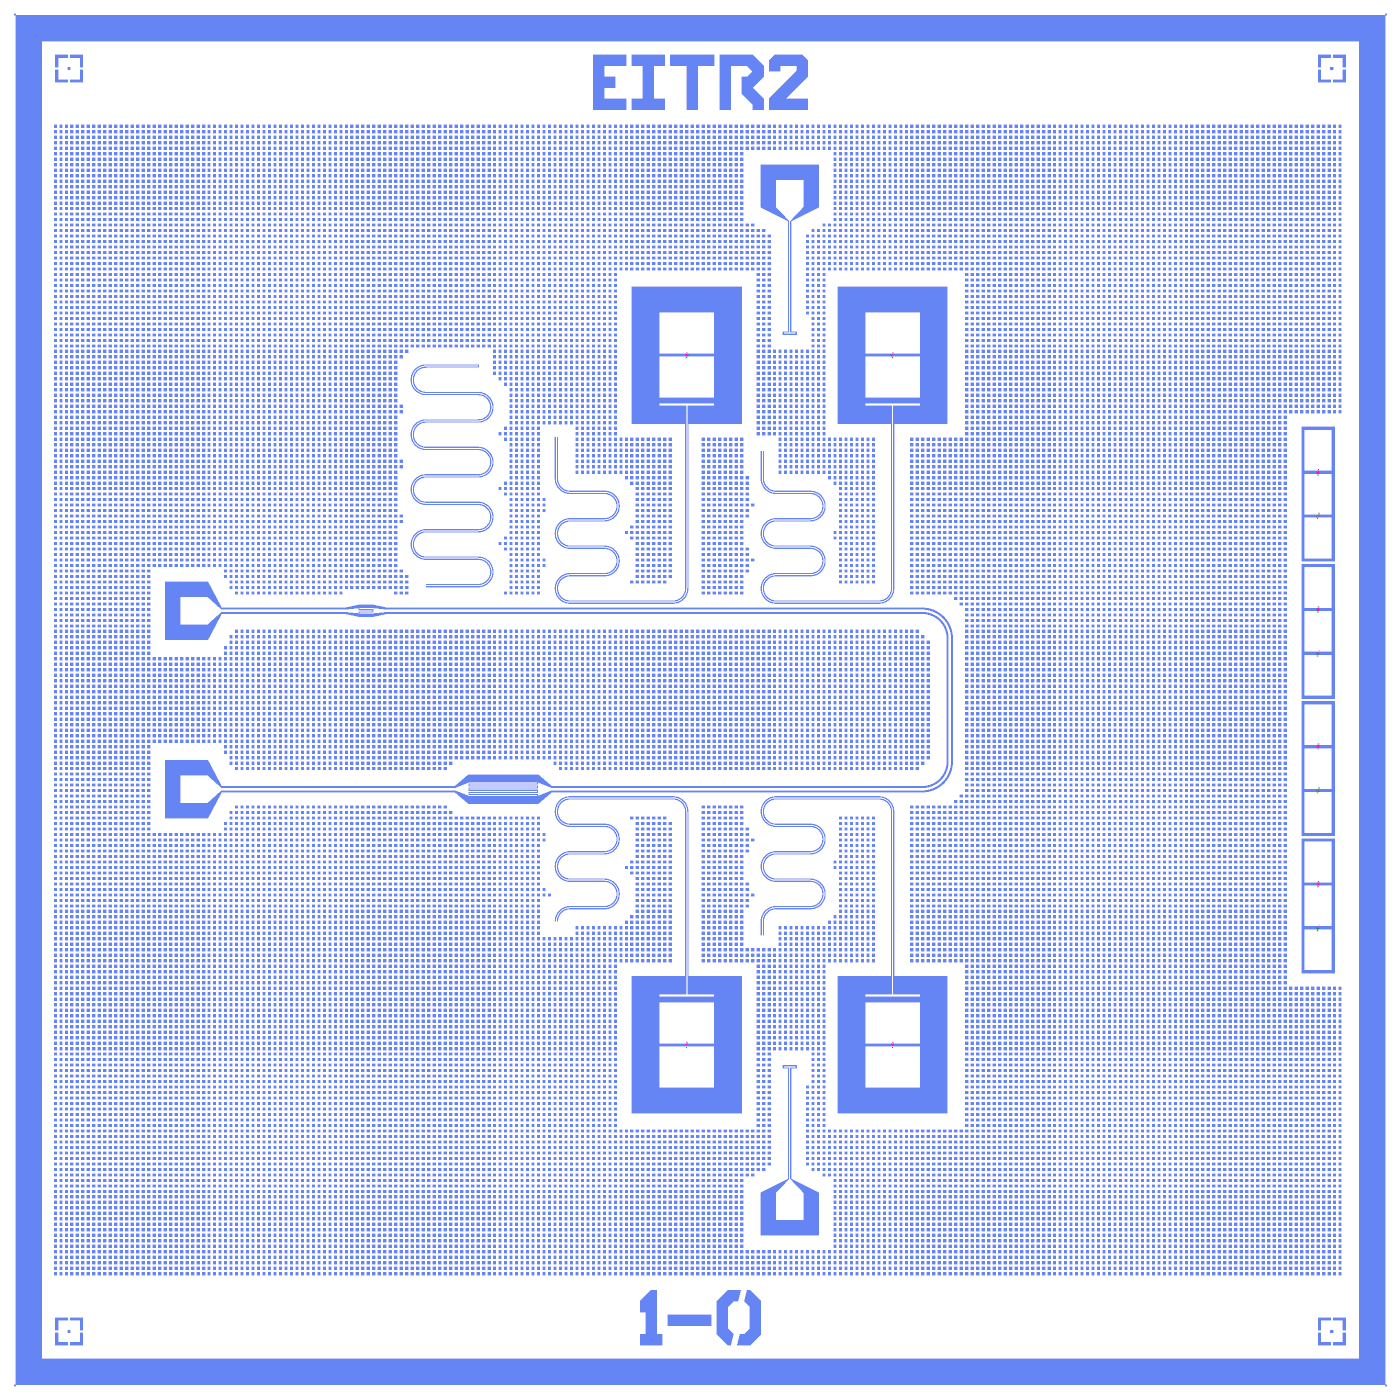

In [20]:
snap_file(OUT / "tuokkola_near_ms_transmon_sample.oas", OUT / "tuokkola_near_ms_transmon_reference.png",
          size=(1400, 1400), width=560);

## 14 · Summary

- **Matches the source:** the four pockets, their positions and sizes, the SQUID / single-junction split, the U filter
  on the GDS's runs between capacitors with the GDS's finger counts, the 900 µm hangers where the GDS has them, the
  shared drive lines; f_r within 0.6 % of the measured 5.85–6.23 GHz; the sample's hole grid (20 µm / 40 µm, 80 µm from the
  line etch), drawn by the build and kept in the mask (46 859 holes).
- **Changed by the PDK:** the frame and device ID, Quantcore trilayer junctions, the four launchpads 100 µm from the
  die edge (longer feed and drive lines), the circuit centred in the die (the sample's off-centre test column is not
  rebuilt).
- **Open PDK design warnings:** `pdk_rn` on all four qubits (R_n 75–188 kΩ: the measured 2.9–4.6 GHz need small
  junctions) and `pdk_fq` on Q2 and Q4 (2.89 / 3.295 GHz, below the 4–8 GHz band). Flagged, not retuned.
- **Known limits:** the LOM lumps the Purcell filter between its series capacitors (κ_r ≈ 10 kHz); the FEM jobs are
  exported, not solved (`RUN_FEM = False`).
- **To check:** the qubit frequency targets 4.047 / 2.890 / 4.593 / 3.295 GHz against arXiv 2407.18778 (the Zenodo
  README has none).